# Metrics

Metrics reach you in four ways. Almost everything you need comes from the first.

| Method | How to get it | Use for |
|---|---|---|
| Result files | Written by default to `results/<scenario>/` | KPIs and scheduler behaviour |
| Application logs | `--UdpFiles=true --PosLog=true` | End-to-end checks, positions |
| ns-3 trace sources | `Config::Connect` in the script | Custom online metrics |
| NS_LOG | Debug build, `LogComponentEnable` | Debugging one UE |

`tools/morev2x_results.py` parses all the files, so you do not need the column positions below in your own code.

**Measured on ns-3.22.** The figures here come from `develop`. The ns-3.42 port reproduces them within the confidence intervals, see [notebook 06](06_ns3_migration.ipynb). Commands in this notebook use the `ns-3.22` file names where they differ, see `COMMANDS.txt` for this branch.

In [1]:
import os, subprocess, sys
sys.path.insert(0, os.path.abspath("../../tools"))
import morev2x_results as mr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 90)
mr.apply_chart_style()
os.chdir(mr.ROOT)

In [2]:
run = mr.simulate("rsrp128", "--Vehicles=120", "--simTime=10", "--mcs=13", "--seed=1", "--Periodic", "--RSRP=-128")
files = {name: f[0] for name, f in mr.FILES.items()}
pd.DataFrame({"rows": {f: sum(1 for _ in open(os.path.join(run.folder, f))) for f in os.listdir(run.folder)},
              "MB": {f: round(os.path.getsize(os.path.join(run.folder, f)) / 1e6, 2) for f in os.listdir(run.folder)}})

,rows,MB
ReEvaluationsLog.txt,1187,0.05
ReceivedLog.txt,1695340,69.97
SSPSlog.txt,1208,0.09
CBR_OutputFile.txt,1025,0.02
simREADME.txt,26,0.00
ReservationsLog.txt,600,0.02
SchedulerMap.txt,120,0.00
phyDebugShort.txt,20486,1.04


## 1. Result files

Written in blocks every `SavingPeriod`, 2 s in `HIGHWAY`. **The last block is never flushed**, so a run reports up to `SavingPeriod` less than `simTime`: compute rates from the times in the file, not from `simTime`, or run a little longer. A block is only flushed by the next event of that log, so `SSPSlog.txt` can stay empty when selections stop early, for example with `--pkeep=1`. `ReservationsLog.txt` still counts them.

### `ReceivedLog.txt`, the main file
One row per transmission, per receiver in decoding range or below sensitivity. Written by `NrV2XSpectrumPhy`.

| Column | Meaning |
|---|---|
| `rxTime` | s, rounded down to 10 ms |
| `packetID` | Global packet counter |
| `distance` | Tx-Rx distance (m) |
| `txID`, `rxID` | Node ids |
| `decoded` | 1 or 0 |
| `lossType` | Outcome, below |
| `txIndex` | 1 initial, 2 re-transmission |
| `trigger` | What caused the selection, 0 to 4 |
| `announced` | The resource was announced by an earlier SCI |
| `latency` | s, from generation to reception, rounded to 0.1 ms |

| `lossType` | Meaning |
|---|---|
| 9 | Decoded |
| 0 | Below sensitivity |
| 1 | Half duplex, the receiver was transmitting |
| 2 | Propagation: lost to the BLER curves with noise only |
| 3 | Collision: would have been decoded without interference |

The **row order of this file changes between runs of one binary**, because receivers flush in pointer order. The content does not, so sort before comparing two runs. `tools/fingerprint.sh` does.

Limits: a row needs the receiver in `MetricsMinX` to `MetricsMaxX`, 0 to 3500 m by default (`HIGHWAY` widens it for SUMO), and a re-transmitted TB gives two rows. `mr.first_copies` keeps one per packet and receiver.

### `SSPSlog.txt`, one row per selected resource
Written by `V2XSelectResources`. `node, time, frame, subframe, iterations, rsrpThreshold, nCSRfinal, nCSRpastTx, nCSRinitial, Cresel, RRI, RRIslots, PDB, txPerTB, grantIndex, trigger, nextFrame, nextSubframe, rbStart, rbLen, reEvalEnabled, reEvalFrame, reEvalSubframe`

Use it for candidate statistics and to see how far the threshold had to rise.

### `phyDebugShort.txt`, one row per transmission
`node, packet, genTime, txIndex, txTime, frame, subframe, Cresel, RRI, psschRbStart, psschRbLen, psschRbLenTb, pscchRbStart, pscchRbLen`

`psschRbLen` is what was reserved, `psschRbLenTb` what was used. `txTime - genTime` is the access delay.

### `CBR_OutputFile.txt`
`node, cbr, time`. Sampled every 0.5 s per UE, over the last 100 ms, counting subchannels with RSSI at or above `RSSIthreshold` (-88 dBm in `HIGHWAY`). Only UEs with `x` in `CbrMinX` to `CbrMaxX`, **1500 to 3500 m by default**.

### `ReservationsLog.txt`, counters per UE and period
`node, time, unusedSubchannelRatio, unusedReservations, reservations, latencyReselections, sizeReselections, counterReselections, transmissions`

### `ReEvaluationsLog.txt`, one row per check
`freshGrant, node, time, packet, checkedTxIndex, frame, subframe, lastFrame, lastSubframe, csr, checkFrame, checkSubframe, reselected`

Written even without `--ReEvaluation`, where `reselected` means "would have changed".

### Debug lists
`m_debugNode` in the MAC, 0 by default so off, writes `SafileAlert.txt`, `L1fileAlert.txt`, `L2fileAlert.txt` and `UnimoreSensingDebug.txt`: the complete candidate lists of one UE at every selection. Setting it needs a code change at `m_debugNode = 0`.

### Commented out in the source
`collisionCounters.txt`, `receivedPower.csv`, `RxPowerFile.csv`, `SNRfile.csv`, `delayRLC.csv`, `tbRxFile.csv`, `RLCbufferSize.txt`, `PacketsType.txt`, `SSPSlog_EXT.txt`, `ReEvaluationsLog_EXT.txt`, `phyDebugALL.txt`, `CBRlist_1.txt`. Each works if uncommented.

### Over many runs
`tools/run_sweep.py` runs every combination of a YAML file and collects `mr.summary` of each run into `summary.csv`. Use it for confidence intervals: list `runNo: [1, 2, 3, ...]`.

## 2. Application logs

Both are off by default.

| Option | File | Columns |
|---|---|---|
| `--UdpFiles=true` | `TxFile.txt` | `packet, time, node, x, y, messageType, trafficType, size` |
| | `RxFile.txt` | `packet, genTime, rxTime, delay, node, size, distance, hops, messageType, trafficType, alreadyReceived` |
| `--PosLog=true` | `posFile.txt` | `time, node, x, y, z, vx, vy, vz, trafficType, inside`, every 100 ms |

`RxFile.txt` holds only successful receptions, so it cannot give a PDR alone. `TxFile` and `RxFile` append and reopen the file for every packet, which is slow in large runs. In `posFile.txt` velocity is a difference of positions.

## 3. ns-3 trace sources

Connect from the script with `Config::Connect`, for custom online metrics.

| Source | Fires? | Gives |
|---|---|---|
| `NrV2XSpectrumPhy/SlPhyReception` | Yes | PSSCH reception, per TB |
| `NrV2XSpectrumPhy/SlPscchReception` | Yes | PSCCH reception, per SCI |
| `NistLteRlc/TxPDU`, `RxPDU` | Yes | RLC bytes and delay |
| `NistLtePdcp/TxPDU`, `RxPDU` | Yes | PDCP bytes and delay |
| `MultiModelSpectrumChannel/PathLoss` | Yes | Loss of each Tx-Rx pair |
| `MultiModelSpectrumChannel/Gain` | **No, never fired** | Declared but unused |
| `NrV2XUeMac/SlUeScheduling`, `SlSharedChUeScheduling` | **No, never fired** | Declared but unused |

## 4. Logging

`NS_LOG_UNCOND` and `NS_LOG_*` are compiled out of the optimized build, so use a debug build (see `COMMANDS.txt`) and enable components as listed at the top of `main` in `scratch/HIGHWAY.cc`. `NrV2XUeMac` at `LOG_LEVEL_ALL` prints every candidate, keep such runs short.

## KPIs

### Packet delivery ratio
Decoded over attempted, per distance. Without combining, a re-transmitted packet would be counted twice.

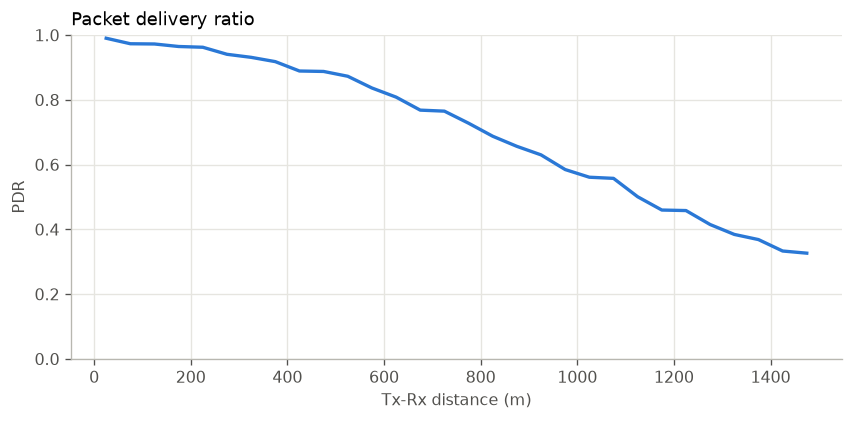

In [3]:
fig, ax = plt.subplots()
pdr = mr.pdr_by_distance(run.rx, bin_m=50, max_m=1500)
ax.plot(pdr.index, pdr.values, color=mr.SERIES_COLORS[0])
ax.set_xlabel("Tx-Rx distance (m)")
ax.set_ylabel("PDR")
ax.set_ylim(0, 1)
ax.set_title("Packet delivery ratio")
plt.tight_layout()

### Why packets are lost
`lossType` separates scheduling problems (collisions) from radio problems. This is the metric that shows whether tuning the scheduler can help at a given distance.

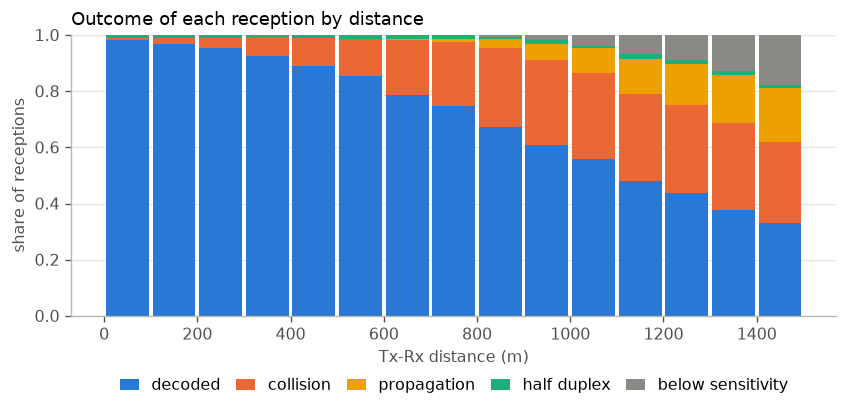

In [4]:
table = mr.loss_breakdown(run.rx, bin_m=100, max_m=1500)
order = [c for c in ["decoded", "collision", "propagation", "half duplex", "below sensitivity"] if c in table]
colors = dict(zip(order, [mr.SERIES_COLORS[0], mr.SERIES_COLORS[1], mr.SERIES_COLORS[3], mr.SERIES_COLORS[2], mr.NEUTRAL]))
fig, ax = plt.subplots()
bottom = np.zeros(len(table))
for column in order:
    ax.bar(table.index, table[column], bottom=bottom, width=92, label=column, color=colors[column])
    bottom += table[column].values
ax.set_xlabel("Tx-Rx distance (m)")
ax.set_ylabel("share of receptions")
ax.grid(axis="x", visible=False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.17), columnspacing=1.0, handlelength=1.2)
ax.set_title("Outcome of each reception by distance")
plt.tight_layout()

### Latency
From generation to reception, so it includes waiting for the reserved slot. With SPS it is bounded by the PDB by construction.

,count,mean,std,min,50%,95%,99%,max
ms,749952.0,29.7,27.7,3.0,17.5,89.1,99.3,100.8


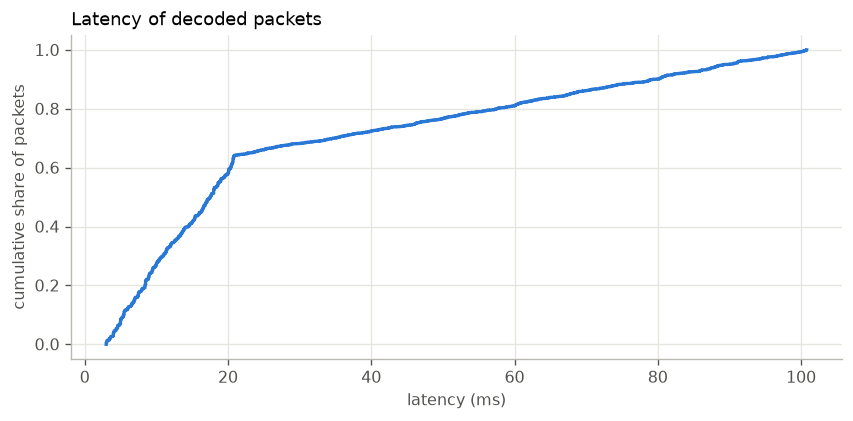

In [5]:
fig, ax = plt.subplots()
values = np.sort(run.rx[run.rx.decoded == 1].latency.to_numpy() * 1000)
ax.plot(values, np.linspace(0, 1, len(values)), color=mr.SERIES_COLORS[0])
ax.set_xlabel("latency (ms)")
ax.set_ylabel("cumulative share of packets")
ax.set_title("Latency of decoded packets")
plt.tight_layout()
mr.latency_summary(run.rx).round(1).to_frame("ms").T

### Packet inter-reception time and Age of Information
Consecutive losses hurt a safety application more than the PDR suggests. Both come from `ReceivedLog.txt`, for pairs closer than 300 m. `mr.age_of_information` uses the sawtooth area between updates.

`rxTime` has 10 ms resolution, so these numbers are good to about that.

In [6]:
gaps = mr.inter_reception_times(run.rx)
aoi = mr.age_of_information(run.rx)
pd.DataFrame({"PIR (ms)": gaps.describe(percentiles=[.5, .95, .99]),
              "AoI (ms)": aoi.aoi.describe(percentiles=[.5, .95, .99]),
              "Peak AoI (ms)": aoi.paoi.describe(percentiles=[.5, .95, .99])}).round(1)

,PIR (ms),AoI (ms),Peak AoI (ms)
count,193565.0,1618.0,1618.0
mean,58.5,94.7,132.1
std,50.4,42.0,51.2
min,10.0,14.6,24.6
50%,20.0,103.2,152.3
95%,100.0,149.6,179.1
99%,150.0,196.3,190.9
max,1900.0,425.3,302.1


### Channel busy ratio

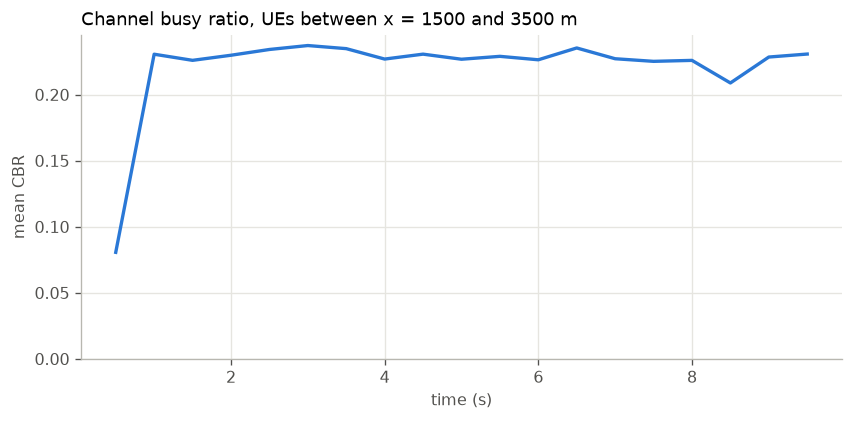

In [7]:
fig, ax = plt.subplots()
cbr = mr.cbr_over_time(run.cbr)
ax.plot(cbr.index, cbr.values, color=mr.SERIES_COLORS[0])
ax.set_xlabel("time (s)")
ax.set_ylabel("mean CBR")
ax.set_ylim(bottom=0)
ax.set_title("Channel busy ratio, UEs between x = 1500 and 3500 m")
plt.tight_layout()

The first 0.5 to 1 s is a ramp-up: applications start at random times within the first second, and sensing needs one period. Leave out the first second when averaging.

### Scheduler health
`rsrpThreshold` above the configured value means the 20 % rule fired. `unusedSubchannelRatio` shows reserved RBs not used by the TB.

In [8]:
selection = pd.Series({
    "share of selections that raised the threshold": (run.ssps.iterations > 1).mean(),
    "mean final threshold (dBm)": run.ssps.rsrpThreshold.mean(),
    "mean candidates left in L1 / after past Tx": (run.ssps.nCSRfinal / run.ssps.nCSRpastTx).mean(),
    "re-evaluation hit rate": run.reevaluations.reselected.mean(),
    "unused reservations per UE per period": run.reservations.unusedReservations.mean(),
})
selection.round(3).to_frame("value")

,value
share of selections that raised the threshold,0.170
mean final threshold (dBm),-125.623
mean candidates left in L1 / after past Tx,0.424
re-evaluation hit rate,0.105
unused reservations per UE per period,0.000
